# RetailAssist: complete executable walkthrough
DSA 8401 | Admission 109419

AI-assisted implementation: read `AI_USE.md`. Historical Indian catalogue; INR only; availability unknown. This notebook runs the same modules as the scripted pipeline. It does not call a paid LLM by default. Run the documented pipeline first, or set `REBUILD=True` below for a full rebuild.

## 1. Locate the project and import the implementation
Run cells in order. The working directory can be the project root or notebooks folder. Dependencies must be installed from requirements-dev.txt.

In [1]:
from pathlib import Path
import sys, json, os
ROOT = Path.cwd()
if not (ROOT / 'src/retailassist').exists(): ROOT = ROOT.parent
assert (ROOT / 'src/retailassist').exists(), 'Start from project root or notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
import numpy as np
from IPython.display import display
from retailassist.core import prepare, Engine, explain
print('Project:', ROOT.name)

Project: retailassist


## 2. Rebuild from raw data when needed
`pipeline.main()` downloads the pinned source, cleans it, fits TF-IDF and SVD, embeds the catalogue, and saves artifacts. REBUILD=False uses the already executed build. This avoids expensive retraining every time you explore a result.

In [2]:
REBUILD = False
if REBUILD or not (ROOT/'artifacts/retriever.joblib').exists():
    import subprocess
    subprocess.run([sys.executable, '-m', 'retailassist.pipeline'], cwd=ROOT, check=True,
                   env={**os.environ,'PYTHONPATH':str(ROOT/'src')})
manifest = json.loads((ROOT/'artifacts/manifest.json').read_text())
display(manifest)

{'source': 'https://huggingface.co/datasets/jason1966/PromptCloudHQ_flipkart-products/resolve/ac16731c75907ab9f212c372ec637c00f257c36a/flipkart_com-ecommerce_sample.csv',
 'raw_sha256': '56f8f699c9e847356666c2eab3c3ab1244340f6a98ad08e39ea2199ebe993ad1',
 'rows': 19920,
 'created_utc': '2026-11-19T12:00:09.394991+00:00',
 'seed': 42,
 'encoder': 'sentence-transformers/all-MiniLM-L6-v2',
 'encoder_revision': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41',
 'currency': 'INR',
 'availability': 'unknown',
 'split': 'Catalogue indexed in full; evaluation queries split into dev/test. No interactions available.'}

## 3. Inspect semi-raw data
A rating stored as "No rating available" is not a numeric zero. A missing stock field does not imply availability. Preserve INR prices and do not invent missing values.

In [3]:
raw = pd.read_csv(ROOT/'data/raw/catalogue.csv')
print('Raw shape:', raw.shape)
display(raw[['product_name','brand','discounted_price','product_rating']].head(8))
display(raw.isna().sum().sort_values(ascending=False).to_frame('Missing cells'))

Raw shape: (20000, 15)


,product_name,brand,discounted_price,product_rating
0,Alisha Solid Women's Cycling Shorts,Alisha,379.0,No rating available
1,FabHomeDecor Fabric Double Sofa Bed,FabHomeDecor,22646.0,No rating available
2,AW Bellies,AW,499.0,No rating available
3,Alisha Solid Women's Cycling Shorts,Alisha,267.0,No rating available
4,Sicons All Purpose Arnica Dog Shampoo,Sicons,210.0,No rating available
5,Eternal Gandhi Super Series Crystal Paper Weig...,Eternal Gandhi,430.0,No rating available
6,Alisha Solid Women's Cycling Shorts,Alisha,479.0,No rating available
7,FabHomeDecor Fabric Double Sofa Bed,FabHomeDecor,22646.0,No rating available


,Missing cells
brand,5864
retail_price,78
discounted_price,78
product_specifications,14
image,3
description,2
uniq_id,0
crawl_timestamp,0
product_url,0
product_name,0


## 4. Run and explain preprocessing
Invalid prices and duplicate IDs are removed; brand, ratings and descriptions have explicit missingness policies. Inspect `prepare` to understand each transformation.

In [4]:
clean, audit = prepare(raw)
display(audit)
display(clean[['id','name','category','price','rating','availability']].head())
assert clean.id.is_unique and clean.price.gt(0).all()
assert clean.availability.eq('unknown').all()

{'raw_rows': 20000,
 'missing_by_column': {'uniq_id': 0,
  'crawl_timestamp': 0,
  'product_url': 0,
  'product_name': 0,
  'product_category_tree': 0,
  'pid': 0,
  'retail_price': 78,
  'discounted_price': 78,
  'image': 3,
  'is_FK_Advantage_product': 0,
  'description': 2,
  'product_rating': 0,
  'overall_rating': 0,
  'brand': 5864,
  'product_specifications': 14},
 'clean_rows': 19920,
 'removed_rows': 80,
 'unknown_rating': 18081,
 'unknown_brand': 5851}

,id,name,category,price,rating,availability
0,SRTEH2FF9KEDEFGF,Alisha Solid Women's Cycling Shorts,Clothing,379.0,NaN,unknown
1,SBEEH3QGU7MFYJFY,FabHomeDecor Fabric Double Sofa Bed,Furniture,22646.0,NaN,unknown
2,SHOEH4GRSUBJGZXE,AW Bellies,Footwear,499.0,NaN,unknown
3,SRTEH2F6HUZMQ6SJ,Alisha Solid Women's Cycling Shorts,Clothing,267.0,NaN,unknown
4,PSOEH3ZYDMSYARJ5,Sicons All Purpose Arnica Dog Shampoo,Pet Supplies,210.0,NaN,unknown


## 5. Explore imbalance, prices and missingness
Large categories dominate the corpus. Descriptive plots describe this snapshot, not market demand or sales volume.

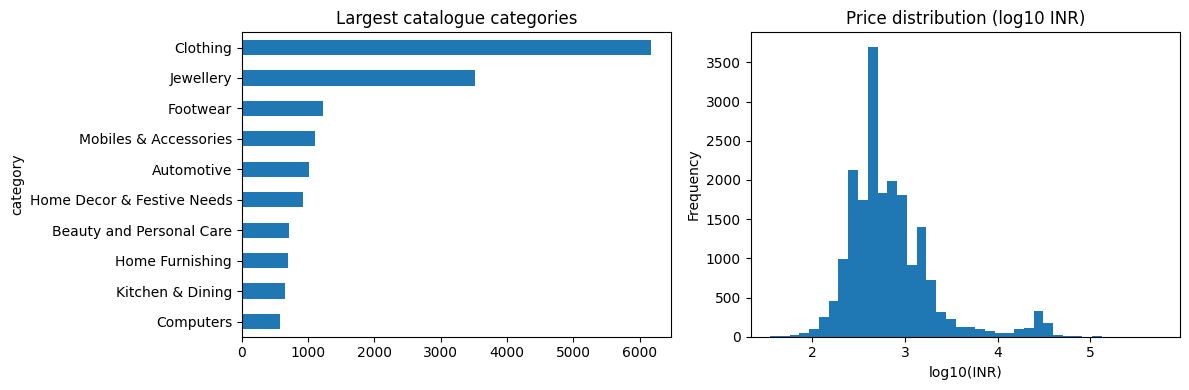

count     19920.000000
mean       1973.454418
std        7333.951480
min          35.000000
10%         249.000000
50%         550.000000
90%        1994.100000
99%       31920.860000
max      571230.000000
Name: price, dtype: float64

In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12,4))
clean.category.value_counts().head(10).sort_values().plot.barh(ax=axes[0],title='Largest catalogue categories')
np.log10(clean.price).plot.hist(bins=40,ax=axes[1],title='Price distribution (log10 INR)')
axes[1].set_xlabel('log10(INR)'); plt.tight_layout(); plt.show()
display(clean.price.describe(percentiles=[.1,.5,.9,.99]))

## 6. Inspect the fitted representations
TF-IDF learns term statistics; SVD learns latent co-occurrence factors. MiniLM is pretrained and not fine-tuned here. Full catalogue indexing is appropriate for search; held-out queries test retrieval.

In [6]:
engine = Engine()
print('TF-IDF matrix:', engine.b['tfidf'].shape)
print('LSA matrix:', engine.b['latent'].shape)
print('Semantic matrix:', engine.b.get('embeddings', np.empty((0,0))).shape)
print('SVD explained variance sum:', engine.b['svd'].explained_variance_ratio_.sum())
terms = engine.b['vectorizer'].get_feature_names_out()
weights = engine.b['svd'].components_[0]
print('First latent direction terms:', terms[np.argsort(weights)[-12:]].tolist())

TF-IDF matrix: (19920, 40000)
LSA matrix: (19920, 128)
Semantic matrix: (19920, 384)
SVD explained variance sum: 0.3327045874688525
First latent direction terms: ['solid', 'casual', 'buy', 'men', 'shirts', 'com', 'flipkart', 'flipkart com', 'online', 'clothing', 'shirt', 'women']


## 7. Trace query parsing and hard filters
Structured constraints express confirmed user intent. Prices never exceed the accepted ceiling. The parser handles common budget phrases but is not a general language-understanding system.

In [7]:
query = 'comfortable running shoes under INR 1500'
print(engine.parse(query))
result = engine.search(query,method='hybrid',constraints={'category':'Footwear'})
display(pd.DataFrame(result['products']))
assert all(p['price'] <= 1500 and p['category']=='Footwear' for p in result['products'])
print(explain(result)['answer'])

{'max_price': 1500.0}


/private/tmp/retailassist-venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/private/tmp/retailassist-venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,id,name,brand,category,price,currency,rating,availability,url,score
0,SHOECEHRSPNUVTHH,Bostan Running Shoes,Unknown,Footwear,499.0,INR,None,unknown,http://www.flipkart.com/bostan-running-shoes/p...,0.526021
1,SHOEJ5YSJMX2HXRF,N Five Running Shoes,N Five,Footwear,959.0,INR,None,unknown,http://www.flipkart.com/n-five-running-shoes/p...,0.509320
2,SHOEJ9KH22WQXKU2,CANMP Running Shoes,CANMP,Footwear,299.0,INR,None,unknown,http://www.flipkart.com/canmp-running-shoes/p/...,0.506146
3,SHOEG7FXJFJDFPBD,"WorldWearFootwear Running Shoes, Walking Shoes",WorldWearFootwear,Footwear,380.0,INR,None,unknown,http://www.flipkart.com/worldwearfootwear-runn...,0.475678
4,SHOEGRUNZPJDGG2Y,ADIWALK ATOM Running Shoes,ADIWALK,Footwear,599.0,INR,None,unknown,http://www.flipkart.com/adiwalk-atom-running-s...,0.465096


Bostan Running Shoes [SHOECEHRSPNUVTHH]: INR 499.00; brand: Unknown; category: Footwear; availability: unknown.
N Five Running Shoes [SHOEJ5YSJMX2HXRF]: INR 959.00; brand: N Five; category: Footwear; availability: unknown.
CANMP Running Shoes [SHOEJ9KH22WQXKU2]: INR 299.00; brand: CANMP; category: Footwear; availability: unknown.
WorldWearFootwear Running Shoes, Walking Shoes [SHOEG7FXJFJDFPBD]: INR 380.00; brand: WorldWearFootwear; category: Footwear; availability: unknown.
ADIWALK ATOM Running Shoes [SHOEGRUNZPJDGG2Y]: INR 599.00; brand: ADIWALK; category: Footwear; availability: unknown.


## 8. Compare lexical and semantic rankings
Inspect actual items for paraphrased intent. A larger score is not a calibrated probability, and different methods have different score distributions.

In [8]:
for method in ['tfidf','lsa','semantic','hybrid']:
    r = engine.search('footwear for jogging',method=method,k=3,constraints={'category':'Footwear'})
    print('\n',method)
    display(pd.DataFrame(r['products'])[['id','name','price','score']])


 tfidf


,id,name,price,score
0,SHODZDFBUZVTNZUH,Select Sporty Running Shoes,449.0,0.173321
1,SHODZ9AKGHEYPWGT,Select Sporty Walking Shoes,449.0,0.170615
2,SHOE58EKXSEYAYX6,Trilokani Sport Walking Shoes,989.0,0.170454



 lsa


,id,name,price,score
0,SHOEBG6ZRCKHXNXE,Steppings Wedges Casuals Shoes,2309.0,0.776701
1,SNDEFKFNCHPREWPN,FIla ECHO Women Sports Sandals,999.0,0.758286
2,SHOEDP7ZGYFKGWNH,Bonzer Bellies,499.0,0.745506



 semantic


,id,name,price,score
0,SHOEG7FXJFJDFPBD,"WorldWearFootwear Running Shoes, Walking Shoes",380.0,0.673418
1,SHOEJ5YSJMX2HXRF,N Five Running Shoes,959.0,0.642134
2,SHOEBG6ZUGTSDGBU,Steppings Running Shoes Casuals Shoes,2589.0,0.630568



 hybrid


,id,name,price,score
0,SHOEG7FXJFJDFPBD,"WorldWearFootwear Running Shoes, Walking Shoes",380.0,0.514908
1,SHODZDFBUZVTNZUH,Select Sporty Running Shoes,449.0,0.502446
2,SHOEJ5YSJMX2HXRF,N Five Running Shoes,959.0,0.489276


## 9. Test abstention, currency and unknown stock
Conservative refusal is appropriate when accepted constraints cannot be verified.

In [9]:
assert engine.search('running shoes',constraints={'max_price':1})['products']==[]
assert engine.search('running shoes',constraints={'in_stock':True})['products']==[]
try:
    engine.search('laptop below KSh 80000')
except ValueError as e:
    print('Expected validation:', e)

Expected validation: Catalogue prices are INR. Currency conversion is not supported; specify INR.


## 10. Inspect the silver benchmark
Queries and rule-based judgments are AI-authored weak labels. They do not represent human preferences. Test intent families overlap with development; this is exploratory evaluation.

In [10]:
from retailassist.evaluate import judgments, metrics, main as evaluate
queries=json.loads((ROOT/'data/queries.json').read_text())
display(pd.DataFrame(queries))
q=queries[6]
relevant=judgments(clean,q)
print('Example query:',q['query'],'Silver positives:',len(relevant))
display(clean[clean.id.isin(relevant)][['id','name','price']].head())

,id,split,query,pattern,category,max_price,brand
0,q01,dev,running shoes under INR 1500,running,Footwear,1500.0,NaN
1,q02,dev,ceramic coffee mug under INR 500,mug,Kitchen & Dining,500.0,NaN
2,q03,dev,decorative table lamp,table lamp,NaN,NaN,NaN
3,q04,dev,keyboard for typing on my computer,keyboard,Computers,NaN,NaN
4,q05,dev,cotton shirt for men,shirt,Clothing,NaN,NaN
5,q06,dev,gold ring,ring,Jewellery,NaN,NaN
6,q07,test,comfortable footwear for jogging under INR 2000,running,Footwear,2000.0,NaN
7,q08,test,cup for a hot drink under INR 400,mug,Kitchen & Dining,400.0,NaN
8,q09,test,light for a bedside table,table lamp,NaN,NaN,NaN
9,q10,test,cover to protect my Samsung phone under INR 600,cover|case,Mobiles & Accessories,600.0,NaN


Example query: comfortable footwear for jogging under INR 2000 Silver positives: 24


,id,name,price
327,SHOEH76627H5HRHM,JQR JQR Sports Shoes Running Shoes,1299.0
329,SHOEH7622HVGTZUF,JQR JQR Sports Shoes Running Shoes,999.0
446,SHOECEHRSPNUVTHH,Bostan Running Shoes,499.0
1133,SHOEJ5YSJMX2HXRF,N Five Running Shoes,959.0
1136,SHOEJ9KH22WQXKU2,CANMP Running Shoes,299.0


## 11. Recompute actual ranking metrics
Precision divides by five; recall divides by all silver positives; MRR rewards the first hit; NDCG discounts rank. Zero-judgment queries are explicitly excluded from summary means, but retained in per-query output.

split   method  queries  queries_with_judgments  zero_judgment_queries  precision_at_5  recall_at_5  mrr_at_5  ndcg_at_5  latency_ms  ndcg_ci_low  ndcg_ci_high
  dev   hybrid        6                       6                      0        1.000000     0.209965  1.000000   1.000000  175.969917     1.000000      1.000000
  dev      lsa        6                       6                      0        0.533333     0.017924  0.500000   0.501005  170.742556     0.167672      0.833333
  dev semantic        6                       6                      0        1.000000     0.209965  1.000000   1.000000  192.346340     1.000000      1.000000
  dev    tfidf        6                       6                      0        0.933333     0.186079  0.916667   0.915210  166.434701     0.802157      1.000000
 test   hybrid       24                      24                      0        0.800000     0.143857  0.862500   0.812903  178.417396     0.674253      0.927187
 test      lsa       24                 

,split,method,queries,queries_with_judgments,zero_judgment_queries,precision_at_5,recall_at_5,mrr_at_5,ndcg_at_5,latency_ms,ndcg_ci_low,ndcg_ci_high
0,dev,hybrid,6,6,0,1.000000,0.209965,1.000000,1.000000,175.969917,1.000000,1.000000
1,dev,lsa,6,6,0,0.533333,0.017924,0.500000,0.501005,170.742556,0.167672,0.833333
2,dev,semantic,6,6,0,1.000000,0.209965,1.000000,1.000000,192.346340,1.000000,1.000000
3,dev,tfidf,6,6,0,0.933333,0.186079,0.916667,0.915210,166.434701,0.802157,1.000000
4,test,hybrid,24,24,0,0.800000,0.143857,0.862500,0.812903,178.417396,0.674253,0.927187
5,test,lsa,24,24,0,0.558333,0.055217,0.598611,0.555798,172.193323,0.386455,0.733052
6,test,semantic,24,24,0,0.791667,0.139792,0.875000,0.795223,180.692396,0.665714,0.915108
7,test,tfidf,24,24,0,0.716667,0.114606,0.854167,0.733960,168.799910,0.599851,0.854223


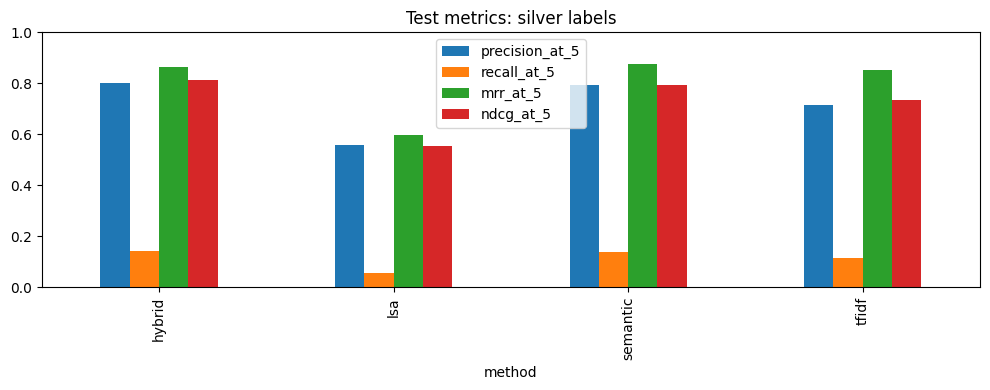

In [11]:
evaluate()
summary=pd.read_csv(ROOT/'reports/metrics.csv')
display(summary)
summary[summary.split.eq('test')].set_index('method')[['precision_at_5','recall_at_5','mrr_at_5','ndcg_at_5']].plot.bar(figsize=(10,4),ylim=(0,1),title='Test metrics: silver labels')
plt.tight_layout();plt.show()

## 12. Inspect failures and verify constraints
Averaging can hide poor intents. Review low-scoring queries and manually judge the recommendations before making any claim of quality.

In [12]:
per=pd.read_csv(ROOT/'reports/per_query_metrics.csv')
display(per[(per.split=='test') & (per.method=='hybrid')].sort_values('ndcg_at_5').head(8))
print('Constraint violations:', per.constraint_violations.sum())
print('Invalid product IDs:', per.invalid_product_ids.sum())
assert per.constraint_violations.sum()==0
assert per.invalid_product_ids.sum()==0
print('Metric sanity:',metrics(['a','x','b'], {'a','b'}))

,query_id,split,method,relevant_count,returned,precision_at_5,recall_at_5,mrr_at_5,ndcg_at_5,latency_ms,constraint_violations,invalid_product_ids,generation_mode
107,q27,test,hybrid,1,5,0.0,0.000000,0.0,0.000000,178.189083,0,0,deterministic
39,q10,test,hybrid,366,5,0.0,0.000000,0.0,0.000000,179.510084,0,0,deterministic
103,q26,test,hybrid,4,5,0.2,0.250000,0.2,0.151020,176.624125,0,0,deterministic
91,q23,test,hybrid,58,5,0.4,0.034483,0.5,0.383566,177.043375,0,0,deterministic
27,q07,test,hybrid,24,5,0.6,0.125000,1.0,0.699215,177.789125,0,0,deterministic
55,q14,test,hybrid,10,5,0.6,0.300000,1.0,0.722727,176.003666,0,0,deterministic
83,q21,test,hybrid,7,5,0.8,0.571429,1.0,0.830420,181.017375,0,0,deterministic
71,q18,test,hybrid,10,5,0.8,0.400000,1.0,0.853932,175.163375,0,0,deterministic


Constraint violations: 0
Invalid product IDs: 0
Metric sanity: {'precision_at_5': 0.4, 'recall_at_5': 1.0, 'mrr_at_5': 1.0, 'ndcg_at_5': 0.9197207891481876}


## 13. Exercise the real API without a running server
FastAPI TestClient runs startup and a prediction through the HTTP contract. Automated tests separately mock external LLM responses. This does not verify a live paid LLM.

In [13]:
from fastapi.testclient import TestClient
from retailassist.api import app
with TestClient(app) as client:
    display(client.get('/health').json())
    response=client.post('/recommend',json={'query':'running shoes under INR 1500','method':'tfidf','constraints':{'category':'Footwear'}})
    assert response.status_code==200
    display(response.json())
    print('Catalogue categories:', len(client.get('/catalogue').json()['categories']))
    insights = client.get('/insights').json()
    display(insights['catalogue'])
    display(pd.DataFrame(insights['evaluation']))

{'status': 'ok',
 'products': 19920,
 'currency': 'INR',
 'semantic_available': True}

{'query': 'running shoes under INR 1500',
 'constraints': {'category': 'Footwear',
  'in_stock': False,
  'max_price': 1500.0},
 'method': 'tfidf',
 'products': [{'id': 'SHOE9AGSGZQNEXGD',
   'name': 'Parbat Nova-Orng-Strips Running Shoes',
   'brand': 'Unknown',
   'category': 'Footwear',
   'price': 999.0,
   'currency': 'INR',
   'rating': None,
   'availability': 'unknown',
   'url': 'http://www.flipkart.com/parbat-nova-orng-strips-running-shoes/p/itme8vqmychbgk6g?pid=SHOE9AGSGZQNEXGD',
   'score': 0.46097359393083004,
   'image_url': 'https://rukminim2.flixcart.com/image/shoe/z/f/u/orange-cnro221-parbat-9-1000x1000-imae8utvyxsfngyq.jpeg'},
  {'id': 'SHOEAEGRVDKXNWXR',
   'name': 'Campus Berlin Running Shoes',
   'brand': 'Unknown',
   'category': 'Footwear',
   'price': 1399.0,
   'currency': 'INR',
   'rating': None,
   'availability': 'unknown',
   'url': 'http://www.flipkart.com/campus-berlin-running-shoes/p/itmeaegrdzftca2e?pid=SHOEAEGRVDKXNWXR',
   'score': 0.447549427444141,

Catalogue categories: 14


{'total_products': 19920,
 'brands': 3485,
 'rated_products': 1839,
 'unknown_brands': 5851,
 'unknown_stock': 19920,
 'median_price': 550.0,
 'currency': 'INR',
 'top_categories': [{'name': 'Clothing', 'count': 6170},
  {'name': 'Jewellery', 'count': 3522},
  {'name': 'Footwear', 'count': 1225},
  {'name': 'Mobiles & Accessories', 'count': 1097},
  {'name': 'Automotive', 'count': 1010},
  {'name': 'Home Decor & Festive Needs', 'count': 927},
  {'name': 'Beauty and Personal Care', 'count': 709},
  {'name': 'Home Furnishing', 'count': 700}],
 'price_distribution': [{'label': 'Under 500', 'count': 9385},
  {'label': '500–999', 'count': 5610},
  {'label': '1,000–1,999', 'count': 3021},
  {'label': '2,000–4,999', 'count': 836},
  {'label': '5,000–9,999', 'count': 243},
  {'label': '10,000–49,999', 'count': 804},
  {'label': '50,000+', 'count': 21}]}

,split,method,queries,queries_with_judgments,zero_judgment_queries,precision_at_5,recall_at_5,mrr_at_5,ndcg_at_5,latency_ms,ndcg_ci_low,ndcg_ci_high
0,dev,hybrid,6,6,0,1.000000,0.209965,1.000000,1.000000,175.969917,1.000000,1.000000
1,dev,lsa,6,6,0,0.533333,0.017924,0.500000,0.501005,170.742556,0.167672,0.833333
2,dev,semantic,6,6,0,1.000000,0.209965,1.000000,1.000000,192.346340,1.000000,1.000000
3,dev,tfidf,6,6,0,0.933333,0.186079,0.916667,0.915210,166.434701,0.802157,1.000000
4,test,hybrid,24,24,0,0.800000,0.143857,0.862500,0.812903,178.417396,0.674253,0.927187
5,test,lsa,24,24,0,0.558333,0.055217,0.598611,0.555798,172.193323,0.386455,0.733052
6,test,semantic,24,24,0,0.791667,0.139792,0.875000,0.795223,180.692396,0.665714,0.915108
7,test,tfidf,24,24,0,0.716667,0.114606,0.854167,0.733960,168.799910,0.599851,0.854223


## 14. Optional LLM, Docker and submission
To enable the hosted LLM, set OPENAI_API_KEY outside the notebook and send use_llm=true. Do not hardcode a key. The LLM chooses IDs; application code renders facts. No real LLM quality score is reported.

Run `docker compose up --build -d` after artifacts exist and Docker is running. Confirm /health and a prediction before claiming deployment success. Review `reports/verification.json` for the actual status of this build.

Read the PDF, README, DATA_CARD and AI_USE. Independently validate relevance labels and prepare to explain all code. This notebook is an executable study aid, not evidence of independent authorship.

The redesigned application includes Ask RetailAssist (semantic AI with deterministic catalogue facts), product detail dialogs, local shortlists and an Insights section. Insights reads the actual saved model evaluation, category counts, rating/brand coverage and INR price distribution. PROJECT_COMPLIANCE.md maps every brief/proposal component to code and evidence. Browser visual QA was blocked; HTTP/API and automated tests are reported separately.